# De Píxeles a Texto Estructurado: Taller Interactivo de OCR Qwen2-VL-2B

Bienvenidos a este taller práctico de **Reconocimiento Óptico de Caracteres (OCR)**. En esta sesión aprenderemos cómo funcionan los modelos de OCR modernos y **pondrás a prueba tus propias fotos o capturas** en tiempo real.

### Requisito previo obligatorio en Google Colab / Kaggle
Antes de ejecutar cualquier celda, activa la GPU gratuita:
1. Ve al menú superior: **Entorno de ejecución** (*Runtime*) > **Cambiar tipo de entorno de ejecución** (*Change runtime type*).
2. En **Acelerador de hardware**, selecciona **T4 GPU**.
3. Haz clic en **Guardar**.

---

### Hoja de Ruta de la Sesión
1. **Entendiendo la imagen como datos:** ¿Qué ve realmente el computador?
2. **El "Hola Mundo" del OCR con `pipeline` (TrOCR):** De una línea de texto a string.
3. **Abriendo la Caja Negra:** Separando el `Processor` (Visión) y el `Model` (Decodificación).
4. **Métricas en OCR:** Calculando el **CER** (*Character Error Rate*) y **WER** (*Word Error Rate*).
5. **Preprocesamiento al rescate:** Cómo el contraste, el giro y la binarización afectan al modelo.
6. **OCR de Nueva Generación (VLMs):** Extracción de documentos completos a **JSON/Markdown** con **Qwen2-VL**.
7. **Laboratorio Interactivo (Sube tu propia foto o usa tu cámara):**
   * **Experimento A:** Sube o toma una foto y compárala: *Imagen Original vs. Preprocesada*.
   * **Experimento B:** **TrOCR (1 línea)** vs. **Qwen2-VL (Documento completo)** sobre tu imagen.
   * **Mini-App Web con Gradio:** Una interfaz gráfica dentro de Colab para arrastrar tus fotos y probar distintos prompts.


## Paso 0: Instalación de Librerías y Verificación de GPU
Instalaremos `transformers`, `accelerate` y `qwen-vl-utils` para los modelos de Hugging Face, `jiwer` para métricas y `gradio` para crear nuestro laboratorio visual donde podrás arrastrar tus propias imágenes.


In [2]:
pip install -q transformers accelerate pillow requests torch torchvision jiwer qwen-vl-utils opencv-python matplotlib gradio


Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps

if torch.cuda.is_available():
    print(f"[OK] GPU detectada correctamente: {torch.cuda.get_device_name(0)}")
    device = "cuda"
else:
    print("[AVISO] No se detectó GPU. Ve a: Entorno de ejecución -> Cambiar tipo de entorno de ejecución -> T4 GPU")
    device = "cpu"



[OK] GPU detectada correctamente: Tesla T4


In [33]:
#IMPORTAR LA API_KEY
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("HF_TOKEN")


In [8]:
from huggingface_hub import login
import os

# Forma recomendada en Google Colab:
# 1. Ve a la barra lateral izquierda de Colab -> Icono de Llave (Secrets)
# 2. Crea un secreto llamado 'HF_TOKEN' con tu token de lectura de Hugging Face (https://huggingface.co/settings/tokens)
# 3. O simplemente déjalo vacío y Colab te pedirá el token de forma interactiva en la consola.
try:
    from google.colab import userdata
    hf_token = userdata.get('HF_TOKEN')
    login(token=hf_token)
    print("[OK] Autenticado automáticamente usando Colab Secrets.")
except Exception:
    print("[AVISO] No se encontró el secreto 'HF_TOKEN'. Por favor ingresa tu token de Hugging Face a continuación:")
    login()

[AVISO] No se encontró el secreto 'HF_TOKEN'. Por favor ingresa tu token de Hugging Face a continuación:


---
## Parte 1: Una imagen son solo números (Píxeles a Tensores)
Para nosotros, una imagen contiene letras claras. Para un modelo de Machine Learning, una imagen es un arreglo tridimensional de números entre `0` (negro) y `255` (blanco) en los canales **R**ed, **G**reen y **B**lue.


Dimensiones de la matriz (Alto, Ancho, Canales RGB): (100, 400, 3)
Rango de valores numéricos: 1 a 255


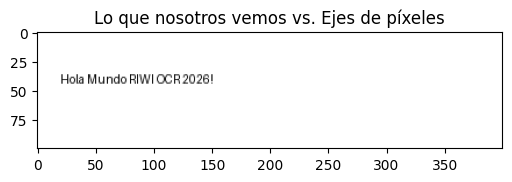

In [29]:
# Creamos una imagen sencilla en blanco con texto negro
img_demo = Image.new('RGB', (400, 100), color=(255, 255, 255))
d = ImageDraw.Draw(img_demo)
d.text((20, 35), "Hola Mundo RIWI OCR 2026!", fill=(0, 0, 0))

matriz_imagen = np.array(img_demo)
print(f"Dimensiones de la matriz (Alto, Ancho, Canales RGB): {matriz_imagen.shape}")
print(f"Rango de valores numéricos: {matriz_imagen.min()} a {matriz_imagen.max()}")

plt.figure(figsize=(6, 2))
plt.imshow(matriz_imagen)
plt.title("Lo que nosotros vemos vs. Ejes de píxeles")
plt.show()


---
## Parte 2: El "Hola Mundo" del OCR con `pipeline` (TrOCR)

Tradicionalmente, el OCR se divide en dos etapas:
1. **Detección (Text Detection):** Encontrar las cajas $(x, y)$ donde hay palabras o líneas.
2. **Reconocimiento (Text Recognition):** Leer qué caracteres hay dentro de ese recorte.

**TrOCR** (*Transformer-based OCR* de Microsoft) es especialista en **Reconocimiento de una sola línea**. Veamos cómo funciona con letra manuscrita.


Cargando modelo TrOCR para texto manuscrito...


preprocessor_config.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.17k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py:1129: InsecureRequestWarning: Unverified HTTPS request is being made to host 'fki.tic.heia-fr.ch'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


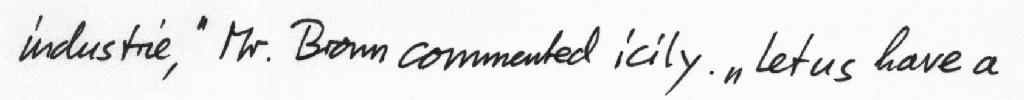


Texto detectado: industry , " Mr. Brown commented icily . " Let us have a


In [10]:
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
import requests
from PIL import Image
import torch

print("Cargando modelo TrOCR para texto manuscrito...")
# Nos saltamos el 'pipeline' problemático y usamos los componentes base directamente
procesador_manuscrito = TrOCRProcessor.from_pretrained("microsoft/trocr-base-handwritten")
modelo_manuscrito = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-handwritten").to(device)

url_manuscrito = "https://fki.tic.heia-fr.ch/static/img/a01-122-02.jpg"
# Añadimos verify=False para ignorar el certificado SSL caducado
img_manuscrito = Image.open(requests.get(url_manuscrito, stream=True, verify=False).raw).convert("RGB")
display(img_manuscrito)

# 1. Convertimos la imagen a tensores
pixel_values = procesador_manuscrito(images=img_manuscrito, return_tensors="pt").pixel_values.to(device)

# 2. Generamos los tokens
with torch.no_grad():
    generated_ids = modelo_manuscrito.generate(pixel_values, max_new_tokens=50)

# 3. Decodificamos a texto legible
texto_detectado = procesador_manuscrito.batch_decode(generated_ids, skip_special_tokens=True)[0]
print("\nTexto detectado:", texto_detectado)

---
## Parte 3: Destripando la "Caja Negra" (`Processor` + `Model`)

¿Qué hace el `pipeline` por dentro? Separa el trabajo en dos componentes:
* **`TrOCRProcessor`:** Redimensiona la imagen a `384x384` píxeles, normaliza los valores RGB y crea el tensor `pixel_values`.
* **`VisionEncoderDecoderModel`:** El *Encoder* mira la imagen dividida en parches y el *Decoder* genera los tokens de texto uno por uno.


preprocessor_config.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

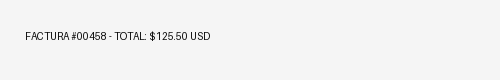

1. Tensor de entrada (Batch, Canales, Alto, Ancho): torch.Size([1, 3, 384, 384])
2. Tokens generados (IDs): [2, 6725, 3764, 27917, 35, 36575, 68, 996, 4, 612, 2]
3. Texto final: 'EXCHANGE: TOTAL $15.00'


In [11]:
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

nombre_modelo = "microsoft/trocr-base-printed"
trocr_processor = TrOCRProcessor.from_pretrained(nombre_modelo)
trocr_model = VisionEncoderDecoderModel.from_pretrained(nombre_modelo).to(device)

# Imagen sintética de una línea impresa
img_impresa = Image.new('RGB', (500, 80), color=(245, 245, 245))
draw = ImageDraw.Draw(img_impresa)
draw.text((25, 30), "FACTURA #00458 - TOTAL: $125.50 USD", fill=(10, 10, 10))
display(img_impresa)

# 1. Preprocesamiento (Imagen -> Tensor)
pixel_values = trocr_processor(images=img_impresa, return_tensors="pt").pixel_values.to(device)
print(f"1. Tensor de entrada (Batch, Canales, Alto, Ancho): {pixel_values.shape}")

# 2. Inferencia (Tensor -> IDs de tokens)
with torch.no_grad():
    generated_ids = trocr_model.generate(pixel_values, max_new_tokens=50)
print(f"2. Tokens generados (IDs): {generated_ids.tolist()[0]}")

# 3. Postprocesamiento (IDs -> Texto)
texto_decodificado = trocr_processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
print(f"3. Texto final: '{texto_decodificado}'")


---
## Parte 4: Midiendo la calidad del OCR (CER y WER)
* **CER (*Character Error Rate*):** Porcentaje de caracteres fallados.
* **WER (*Word Error Rate*):** Porcentaje de palabras falladas.


In [12]:
from jiwer import cer, wer

texto_real = "FACTURA #00458 - TOTAL: $125.50 USD"
prediccion_con_error = "FACTURA #0O458 - TOTAL: $125.5O USD" # Dos ceros '0' cambiados por 'O'

print(f"Real:       {texto_real}")
print(f"Predicción: {prediccion_con_error}\n")
print(f"CER (Error por carácter): {cer(texto_real, prediccion_con_error):.2%}")
print(f"WER (Error por palabra):  {wer(texto_real, prediccion_con_error):.2%}")


Real:       FACTURA #00458 - TOTAL: $125.50 USD
Predicción: FACTURA #0O458 - TOTAL: $125.5O USD

CER (Error por carácter): 5.71%
WER (Error por palabra):  33.33%


---
## Parte 5: OCR de Documentos Completos con Modelos Visión-Lenguaje (Qwen2-VL)

Mientras **TrOCR** solo puede leer un renglón recortado a la vez, un **VLM (Vision-Language Model)** como `Qwen/Qwen2-VL-2B-Instruct` lee **páginas completas** (recibos, cédulas, tablas, notas en cuadernos), entiende la estructura espacial y responde exactamente lo que le pidamos por *prompt*.


In [21]:
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
from qwen_vl_utils import process_vision_info

# Liberamos memoria VRAM directamente sin crear una función errónea
torch.cuda.empty_cache()

vlm_id = "Qwen/Qwen2-VL-2B-Instruct"
print(f"Cargando {vlm_id} en precisión float16...")

vlm_model = Qwen2VLForConditionalGeneration.from_pretrained(
    vlm_id,
    torch_dtype=torch.float16,
    device_map="auto"
)
vlm_processor = AutoProcessor.from_pretrained(vlm_id)
print("[OK] Qwen2-VL listo para analizar imágenes completas.")

Cargando Qwen/Qwen2-VL-2B-Instruct en precisión float16...


config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/56.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

... (4 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[OK] Qwen2-VL listo para analizar imágenes completas.


In [23]:
# Función auxiliar tanto para TrOCR (1 línea) como para Qwen2-VL (Documento completo)
def leer_con_trocr(img_pil):
    """Lee una imagen usando TrOCR (espera una sola línea de texto)."""
    img_rgb = img_pil.convert("RGB")
    pixels = trocr_processor(images=img_rgb, return_tensors="pt").pixel_values.to(device)
    with torch.no_grad():
        ids = trocr_model.generate(pixels, max_new_tokens=64)
    return trocr_processor.batch_decode(ids, skip_special_tokens=True)[0]

def leer_con_qwen_vlm(img_pil, instruccion="Transcribe todo el texto de esta imagen respetando su estructura."):
    """Lee una imagen completa usando Qwen2-VL siguiendo una instrucción."""
    img_rgb = img_pil.convert("RGB")
    # Redimensionamos manteniendo proporción si es gigante para no agotar la VRAM de Colab
    img_rgb.thumbnail((1024, 1024))
    temp_path = "temp_input_vlm.png"
    img_rgb.save(temp_path)

    mensajes = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": temp_path},
                {"type": "text", "text": instruccion}
            ]
        }
    ]
    texto_chat = vlm_processor.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(mensajes)

    inputs = vlm_processor(
        text=[texto_chat],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        generated_ids = vlm_model.generate(**inputs, max_new_tokens=512)

    generated_ids_trimmed = [
        out_ids[len(in_ids):] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]
    return vlm_processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )[0]



---
## Parte 6: Pon a Prueba tus Propias Fotos (Sube un archivo o usa tu Cámara)

Aquí es donde veremos cómo se comportan realmente los modelos con imágenes del mundo real (sombras, fotos inclinadas, letra a mano, recibos arrugados o capturas de pantalla).

Tienes **3 opciones** a continuación:
* **Opción A (Celular / PC):** Ejecuta la celda para subir cualquier foto desde tu dispositivo (`files.upload()`).
* **Opción B (Webcam en vivo):** Toma una foto directamente con la cámara de tu computador mostrando un papel, carnet o recibo.
* **Opción C (Laboratorio Web con Gradio):** Abre una interfaz gráfica interactiva donde puedes arrastrar fotos, rotarlas, aplicarles filtros de OpenCV y comparar **TrOCR vs. Qwen2-VL** con un clic.


In [25]:

import ipywidgets as widgets
from IPython.display import display
import io

# Creamos un widget de carga de archivos
uploader = widgets.FileUpload(
    accept='.jpg, .jpeg, .png', # Acepta imágenes JPG y PNG
    multiple=False              # Solo un archivo a la vez
)

print("Haz clic en 'Upload' para seleccionar y subir una imagen (JPG/PNG):")
display(uploader)

mi_imagen = None
nombre_mi_foto = ""

# Definimos una función que se ejecuta al cargar el archivo
def on_upload_change(change):
    global mi_imagen, nombre_mi_foto
    if uploader.value:
        # En versiones recientes de ipywidgets, el valor es una tupla o dict
        # Obtenemos el primer archivo subido
        uploaded_file = next(iter(uploader.value.values())) if isinstance(uploader.value, dict) else uploader.value[0]
        
        nombre_mi_foto = uploaded_file['metadata']['name'] if 'metadata' in uploaded_file else uploaded_file.get('name', 'imagen.jpg')
        content = uploaded_file['content']
        
        # Abrimos la imagen desde los bytes en memoria
        mi_imagen = Image.open(io.BytesIO(content))
        # Corregimos orientación EXIF automática si fue tomada desde el celular
        mi_imagen = ImageOps.exif_transpose(mi_imagen).convert("RGB")
        
        print(f"\n[OK] Imagen '{nombre_mi_foto}' cargada exitosamente ({mi_imagen.size[0]}x{mi_imagen.size[1]} px):")
        display(mi_imagen.resize((min(500, mi_imagen.width), int(mi_imagen.height * min(500, mi_imagen.width) / mi_imagen.width))))

uploader.observe(on_upload_change, names='value')


Haz clic en 'Upload' para seleccionar y subir una imagen (JPG/PNG):


FileUpload(value=(), accept='.jpg, .jpeg, .png', description='Upload')

---
## Parte 7: Analizando cómo se comportan los modelos con TU imagen

Ahora que cargaste `mi_imagen`, vamos a someterla a dos pruebas clave para observar su comportamiento:
1. **¿Cómo la ve OpenCV al preprocesarla?** (Escala de grises y Binarización adaptativa para eliminar sombras).
2. **¿Cómo responde TrOCR (modelo de 1 línea) vs. Qwen2-VL (modelo de página completa)?**


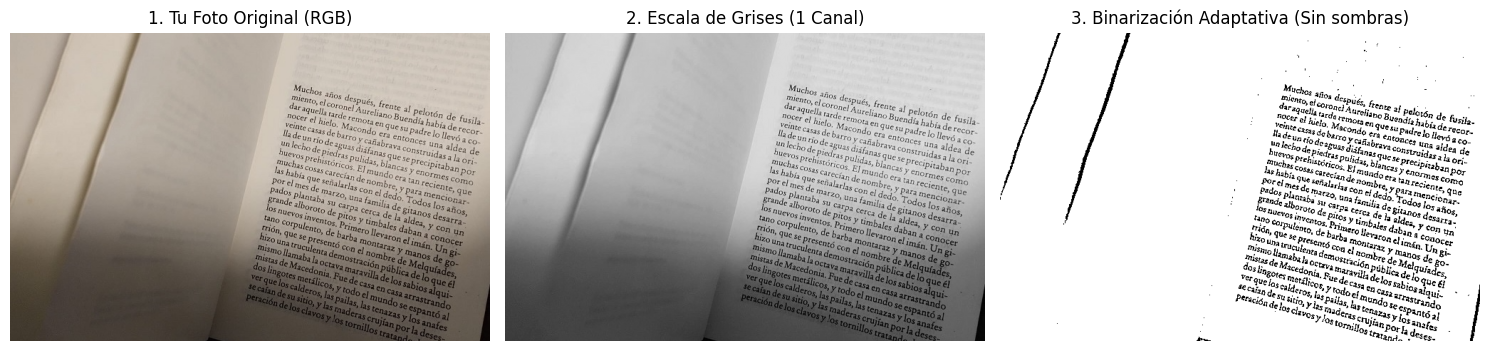

COMPARATIVA DE MODELOS SOBRE TU IMAGEN

[1] Resultado con TrOCR (microsoft/trocr-base-printed):
    (Nota: Si tu foto tiene varios renglones, verás que TrOCR falla o intenta mezclar todo en una sola línea)
    -> Con imagen original:    'L'
    -> Con imagen binarizada:  '/ / CRICEBOOK'

[2] Resultado con Qwen2-VL-2B (Lectura de documento completo + contexto):
```json
{
  "text": "Muchos años después, frente al pelotón de fusilamiento, el coronel Aureliano Buendía había de recordar aquella tarde remota en que su padre lo llevó a conocer el cielo. Macondo era entonces una aldea de veinte casas de barro y canabas construidas a la orilla de un río de aguas diáfanas que se precipitaban por un lecho de piedras pulidas y enormes como huevos prehistóricos. El mundo era tan reciente, que muchas cosas carecían de nombre, y para mencionarlas había que señalarlas con el dedo. Todos los años, por el mes de marzo, por el mes de marzo, por el mes de marzo, por el mes de marzo, por el mes de marzo, p

In [31]:
# 1. Preprocesamiento visual de TU imagen (Original vs Escala de Grises vs Binarizada sin sombras)
img_np = np.array(mi_imagen)
gris_usuario = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)

# Aplicamos umbral adaptativo (excelente cuando tomas fotos con sombra del celular)
binarizada_adaptativa = cv2.adaptiveThreshold(
    gris_usuario, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 21, 10
)
img_binarizada_pil = Image.fromarray(binarizada_adaptativa).convert("RGB")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(mi_imagen)
axes[0].set_title("1. Tu Foto Original (RGB)")
axes[0].axis("off")

axes[1].imshow(gris_usuario, cmap="gray")
axes[1].set_title("2. Escala de Grises (1 Canal)")
axes[1].axis("off")

axes[2].imshow(binarizada_adaptativa, cmap="gray")
axes[2].set_title("3. Binarización Adaptativa (Sin sombras)")
axes[2].axis("off")
plt.tight_layout()
plt.show()

print("="*70)
print("COMPARATIVA DE MODELOS SOBRE TU IMAGEN")
print("="*70)

# Prueba 1: TrOCR
print("\n[1] Resultado con TrOCR (microsoft/trocr-base-printed):")
print("    (Nota: Si tu foto tiene varios renglones, verás que TrOCR falla o intenta mezclar todo en una sola línea)")
res_trocr_orig = leer_con_trocr(mi_imagen)
print(f"    -> Con imagen original:    '{res_trocr_orig}'")
res_trocr_bin = leer_con_trocr(img_binarizada_pil)
print(f"    -> Con imagen binarizada:  '{res_trocr_bin}'")

# Prueba 2: Qwen2-VL
print("\n[2] Resultado con Qwen2-VL-2B (Lectura de documento completo + contexto):")
prompt_usuario = "Transcribe todo el texto visible en esta imagen. Luego, extrae los datos clave en formato JSON."
res_qwen = leer_con_qwen_vlm(mi_imagen, prompt_usuario)
print(res_qwen)



---
## Parte 8: Laboratorio Interactivo con Gradio (Prueba todas las fotos que quieras)

Ejecuta la siguiente celda para levantar una **aplicación web interactiva** directamente aquí en Google Colab (también te dará un link público `.gradio.live` por si quieres abrirlo desde el navegador de tu celular y tomar fotos directo desde ahí).

### ¿Qué puedes experimentar aquí?
1. **Subir o tomar fotos** ilimitadas.
2. **Simular errores del mundo real:** Rotar la imagen (90°, 180°) o activar el filtro de **Binarización Adaptativa** para ver cuándo ayuda y cuándo perjudica.
3. **Comparar cara a cara:** Ver qué responde **TrOCR** vs. **Qwen2-VL** al mismo tiempo y medir cuánto tarda cada uno.


In [32]:
import gradio as gr
import time

def laboratorio_ocr(imagen_entrada, rotacion, filtro_preproc, prompt_vlm):
    if imagen_entrada is None:
        return None, "[AVISO] Por favor sube o toma una foto primero.", "[AVISO] Por favor sube o toma una foto primero."

    # 1. Aplicamos transformaciones elegidas por el estudiante
    img_proc = ImageOps.exif_transpose(imagen_entrada).convert("RGB")
    if rotacion != 0:
        img_proc = img_proc.rotate(-rotacion, expand=True)

    if filtro_preproc == "Escala de Grises":
        gris = cv2.cvtColor(np.array(img_proc), cv2.COLOR_RGB2GRAY)
        img_proc = Image.fromarray(gris).convert("RGB")
    elif filtro_preproc == "Binarización Adaptativa (Quitar sombras)":
        gris = cv2.cvtColor(np.array(img_proc), cv2.COLOR_RGB2GRAY)
        bin_img = cv2.adaptiveThreshold(gris, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 21, 10)
        img_proc = Image.fromarray(bin_img).convert("RGB")
    elif filtro_preproc == "Desenfoque / Foto Borrosa (Simular mala cámara)":
        borrosa = cv2.GaussianBlur(np.array(img_proc), (15, 15), 0)
        img_proc = Image.fromarray(borrosa).convert("RGB")

    # 2. Ejecutamos TrOCR y medimos el tiempo
    t0 = time.time()
    salida_trocr = leer_con_trocr(img_proc)
    t_trocr = time.time() - t0
    texto_trocr = f"Tiempo: {t_trocr:.2f} seg\n\n{salida_trocr}"

    # 3. Ejecutamos Qwen2-VL y medimos el tiempo
    t1 = time.time()
    salida_qwen = leer_con_qwen_vlm(img_proc, prompt_vlm)
    t_qwen = time.time() - t1
    texto_qwen = f"Tiempo: {t_qwen:.2f} seg\n\n{salida_qwen}"

    return img_proc, texto_trocr, texto_qwen

with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("## Laboratorio en Vivo: Sube tu Foto y Experimenta con OCR")
    gr.Markdown("Sube un recibo, etiqueta, apunte en cuaderno o captura de pantalla. Modifica el preprocesamiento para ver cómo reaccionan los modelos.")

    with gr.Row():
        with gr.Column(scale=1):
            img_input = gr.Image(type="pil", label="1. Sube tu foto o usa la cámara")
            rotacion_slider = gr.Radio(
                choices=[0, 90, 180, 270],
                value=0,
                label="2. Rotar imagen (grados) - Prueba ponerla al revés"
            )
            filtro_radio = gr.Dropdown(
                choices=[
                    "Original (Sin filtro)",
                    "Escala de Grises",
                    "Binarización Adaptativa (Quitar sombras)",
                    "Desenfoque / Foto Borrosa (Simular mala cámara)"
                ],
                value="Original (Sin filtro)",
                label="3. Preprocesamiento con OpenCV"
            )
            prompt_box = gr.Textbox(
                value="Transcribe todo el texto de esta imagen y devuelve los datos importantes en un JSON.",
                label="4. Instrucción (Prompt) para el modelo VLM (Qwen2-VL)",
                lines=2
            )
            btn_ejecutar = gr.Button("Procesar Imagen y Comparar Modelos", variant="primary")

        with gr.Column(scale=1):
            img_output = gr.Image(type="pil", label="Imagen que realmente recibe el modelo")
            out_trocr = gr.Textbox(label="Resultado TrOCR (Modelo clásico de 1 sola línea)", lines=4)
            out_qwen = gr.Textbox(label="Resultado Qwen2-VL-2B (Modelo Multimodal de documento completo)", lines=10)

    btn_ejecutar.click(
        fn=laboratorio_ocr,
        inputs=[img_input, rotacion_slider, filtro_radio, prompt_box],
        outputs=[img_output, out_trocr, out_qwen]
    )

# share=True genera un link público para que los estudiantes también puedan abrirlo desde su celular
demo.launch(share=True, debug=False)



/tmp/ipykernel_50/4052271280.py:38: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://a0b72fe33d9c6662cf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
